# RL Inventory Management: Q-learning vs SARSA

**Base paper:** Cuartas & Aguilar (2023), *Hybrid algorithm based on reinforcement learning for smart inventory management*, Journal of Intelligent Manufacturing, 34, 123–149. https://doi.org/10.1007/s10845-022-01982-5

**Research integrity note:** This is a runnable, simplified implementation inspired by the paper, not an exact reproduction. The paper's P1 demand comes from a 21-day example in Ptak & Smith (2016). The exact daily series is not supplied as a downloadable table in the article. The sequence below is an approximation read from its figure, so do not claim exact reproduction unless you obtain and use the original values. The simulator, action space, target level, reward scaling, and synthetic training demand are documented adaptations.

## 1. Research design

We compare **Q-learning** and **SARSA** in the same simulated inventory environment. Both use the same demand sequences, states, actions, and evaluation scenarios. Three reward designs are included, inspired by the paper: R1 (inventory-zone reward), R2 (distance-to-target reward), and R3 (zone reward plus bounded shaping). A simple reorder baseline is included as a reference.

**Paper concepts to understand:** MDP, state, action, transition, reward, Q-learning update, SARSA update, lead time, minimum order quantity (MOQ), inventory target, stockout.

## 2. Imports and settings

In [ ]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

SEED = 42
np.random.seed(SEED)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__, "| Pandas:", pd.__version__)

Python: 3.13.16 | NumPy: 2.1.3 | Pandas: 2.2.3


## 3. P1 demand values

Paper-reported P1 statistics: min 2, mean 10.53, median 9, max 30, standard deviation 6.03; lead time 7 days; MOQ 20. The following 21-day values are **approximate visual readings from Figure 2**, not the original exact data.

Days: 21
Approximate series statistics:


,0
count,21.000000
mean,11.142857
std,6.239277
min,5.000000
25%,6.000000
50%,10.000000
75%,12.000000
max,30.000000


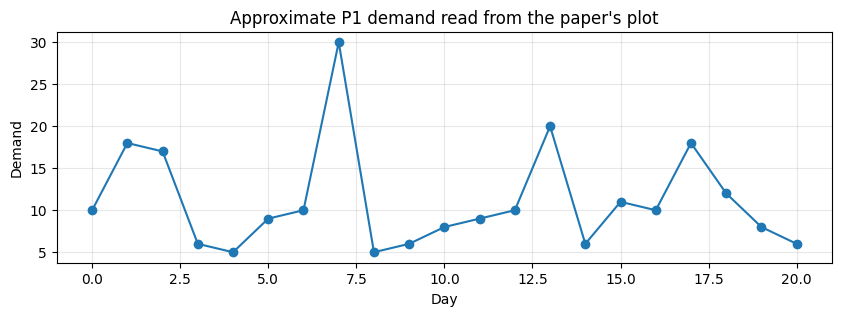

In [ ]:
demand_p1_approx = np.array([10,18,17,6,5,9,10,30,5,6,8,9,10,20,6,11,10,18,12,8,6])
print("Days:", len(demand_p1_approx))
print("Approximate series statistics:")
display(pd.Series(demand_p1_approx).describe())
plt.figure(figsize=(10,3))
plt.plot(demand_p1_approx, marker="o")
plt.title("Approximate P1 demand read from the paper's plot")
plt.xlabel("Day"); plt.ylabel("Demand"); plt.grid(alpha=.3); plt.show()

## 4. Reproducible synthetic training and evaluation demand

The paper describes pseudo-random demand generation for learning. This notebook creates its own reproducible scenarios; these are not the original company data. The synthetic distribution is an explicit experiment assumption.

In [ ]:
def make_demand(n, seed, peak_probability=0.10):
    rng = np.random.default_rng(seed)
    d = rng.integers(2, 16, size=n)
    peaks = rng.random(n) < peak_probability
    d[peaks] = rng.integers(16, 31, size=peaks.sum())
    return d.astype(int)

N_EPISODES = 2000
DAYS_PER_EPISODE = 120
N_EVAL = 25
EVAL_DAYS = 180
train_demands = [make_demand(DAYS_PER_EPISODE, SEED+i) for i in range(N_EPISODES)]
eval_demands = [make_demand(EVAL_DAYS, 10000+i) for i in range(N_EVAL)]

## 5. Inventory environment

State is a discretized tuple of on-hand inventory, target inventory, and days to the next arrival. Actions are no order, 10, 20, 30, or 40 units; any positive order respects MOQ=20. Demand is fulfilled from available stock; unmet demand is recorded. This is a **simplified simulator**: it does not implement every DDMRP detail (such as the full qualified-demand/net-flow calculation).

In [ ]:
LEAD_TIME = 7
MOQ = 20
MAX_INV = 100
ACTIONS = [0, 10, 20, 30, 40]
AVG_DEMAND = float(demand_p1_approx.mean())
TARGET = int(np.clip(round(AVG_DEMAND * LEAD_TIME + MOQ), 20, MAX_INV))
TOR, TOY, TOG = int(.50*TARGET), int(.85*TARGET), int(1.25*TARGET)
print("Target:", TARGET, "| TOR/TOY/TOG:", TOR, TOY, TOG)

class InventoryEnv:
    def __init__(self, demands, reward="R1"):
        self.demands = np.asarray(demands, dtype=int)
        self.reward_name = reward
        self.reset()
    def reset(self):
        self.day, self.stock, self.pipeline = 0, min(TARGET, MAX_INV), []
        self.history = []
        return self.state()
    def state(self):
        stock_bin = int(np.clip(round(self.stock/MAX_INV*10), 0, 10))
        target_bin = int(np.clip(round(TARGET/MAX_INV*10), 0, 10))
        until_arrival = max(0, min((a for a,q in self.pipeline), default=self.day)-self.day)
        return (stock_bin, target_bin, int(np.clip(until_arrival, 0, LEAD_TIME)))
    def reward(self, stock, shortage):
        dist = abs(stock-TARGET)
        zone = 1.0 if TOR < stock <= TOY else (-1.0 if TOY < stock <= TOG else 0.0)
        r2 = 1/(1+dist)
        if self.reward_name == "R1": r = zone
        elif self.reward_name == "R2": r = r2
        elif self.reward_name == "R3":
            shaping = 1-min(dist/max(TARGET,1),1)
            r = zone + .5*shaping
        else: raise ValueError("Reward must be R1, R2, or R3")
        return float(r - .10*shortage)
    def step(self, action_idx):
        # Receive orders arriving today
        arrivals = sum(q for a,q in self.pipeline if a <= self.day)
        self.pipeline = [(a,q) for a,q in self.pipeline if a > self.day]
        self.stock = min(MAX_INV, self.stock + arrivals)
        qty = ACTIONS[action_idx]
        if qty > 0:
            qty = min(MAX_INV, max(qty, MOQ))
            self.pipeline.append((self.day+LEAD_TIME, qty))
        demand = int(self.demands[self.day])
        fulfilled = min(self.stock, demand)
        shortage = max(0, demand-self.stock)
        self.stock -= fulfilled
        reward = self.reward(self.stock, shortage)
        self.history.append(dict(day=self.day, demand=demand, arrivals=arrivals,
                                 order_qty=qty, fulfilled=fulfilled, stockout_units=shortage,
                                 ending_stock=self.stock, reward=reward))
        self.day += 1
        done = self.day >= len(self.demands)
        return (None if done else self.state()), reward, done

Target: 98 | TOR/TOY/TOG: 49 83 122


## 6. Q-learning and SARSA

In [ ]:
ALPHA, GAMMA = 0.15, 0.95
EPS_START, EPS_MIN, EPS_DECAY = 1.0, 0.05, 0.997

def choose_action(Q, state, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.integers(len(ACTIONS)))
    vals = Q[state]
    best = np.flatnonzero(vals == vals.max())
    return int(rng.choice(best))

def train(algorithm, reward_name, seed=SEED):
    rng = np.random.default_rng(seed)
    Q = defaultdict(lambda: np.zeros(len(ACTIONS), dtype=float))
    rewards, epsilon = [], EPS_START
    for ep, demands in enumerate(train_demands):
        env = InventoryEnv(demands, reward_name)
        s = env.reset()
        a = choose_action(Q, s, epsilon, rng)
        total = 0.0
        while True:
            ns, r, done = env.step(a)
            total += r
            if done:
                Q[s][a] += ALPHA*(r-Q[s][a])
                break
            if algorithm == "Q-learning":
                target = r + GAMMA*np.max(Q[ns])
                Q[s][a] += ALPHA*(target-Q[s][a])
                na = choose_action(Q, ns, epsilon, rng)
            else:  # SARSA uses the next action actually selected
                na = choose_action(Q, ns, epsilon, rng)
                target = r + GAMMA*Q[ns][na]
                Q[s][a] += ALPHA*(target-Q[s][a])
            s, a = ns, na
        rewards.append(total)
        epsilon = max(EPS_MIN, epsilon*EPS_DECAY)
    return Q, np.asarray(rewards)

print("Q-learning update: target = reward + gamma * max Q(next_state, action)")
print("SARSA update: target = reward + gamma * Q(next_state, next_action)")

Q-learning update: target = reward + gamma * max Q(next_state, action)
SARSA update: target = reward + gamma * Q(next_state, next_action)


## 7. Train six experiments

In [ ]:
models, curves = {}, {}
for ri, reward_name in enumerate(["R1","R2","R3"]):
    for ai, algorithm in enumerate(["Q-learning","SARSA"]):
        print("Training", algorithm, reward_name)
        Q, curve = train(algorithm, reward_name, seed=SEED+ri*100+ai*1000)
        models[(algorithm,reward_name)] = Q
        curves[(algorithm,reward_name)] = curve
print("Training complete.")

Training Q-learning R1
Training SARSA R1
Training Q-learning R2
Training SARSA R2
Training Q-learning R3
Training SARSA R3
Training complete.


## 8. Training curves

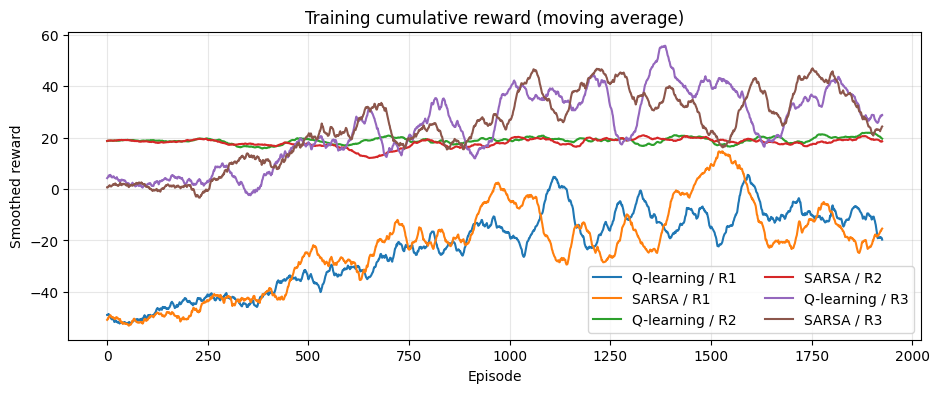

In [ ]:
def smooth(x, window=75):
    return np.convolve(x, np.ones(window)/window, mode="valid") if len(x)>=window else x
plt.figure(figsize=(11,4))
for key, values in curves.items():
    plt.plot(smooth(values), label=f"{key[0]} / {key[1]}")
plt.title("Training cumulative reward (moving average)")
plt.xlabel("Episode"); plt.ylabel("Smoothed reward")
plt.legend(ncol=2); plt.grid(alpha=.3); plt.show()

## 9. Evaluate on shared held-out demand scenarios

In [ ]:
def evaluate(Q, algorithm, reward_name, scenarios):
    rows=[]
    for sid, demands in enumerate(scenarios):
        env=InventoryEnv(demands, reward_name)
        s=env.reset(); total=0.0
        while True:
            a=int(np.argmax(Q[s]))
            ns,r,done=env.step(a); total+=r
            if done: break
            s=ns
        h=pd.DataFrame(env.history)
        demand_total=h.demand.sum()
        rows.append({
            "algorithm":algorithm,"reward_design":reward_name,"scenario":sid,
            "total_reward":total,"stockout_days":int((h.stockout_units>0).sum()),
            "stockout_units":int(h.stockout_units.sum()),
            "fill_rate":h.fulfilled.sum()/demand_total if demand_total else 1.0,
            "mean_ending_inventory":h.ending_stock.mean(),
            "order_count":int((h.order_qty>0).sum()),
            "ordered_units":int(h.order_qty.sum()),
            "mean_target_distance":np.abs(h.ending_stock-TARGET).mean()
        })
    return pd.DataFrame(rows)

evaluation = pd.concat([
    evaluate(models[(alg,rw)],alg,rw,eval_demands)
    for rw in ["R1","R2","R3"] for alg in ["Q-learning","SARSA"]
], ignore_index=True)
display(evaluation.head())
summary = evaluation.groupby(["reward_design","algorithm"],as_index=False).agg(
    mean_reward=("total_reward","mean"), std_reward=("total_reward","std"),
    mean_stockout_days=("stockout_days","mean"), mean_stockout_units=("stockout_units","mean"),
    mean_fill_rate=("fill_rate","mean"), mean_inventory=("mean_ending_inventory","mean"),
    mean_order_count=("order_count","mean"), mean_ordered_units=("ordered_units","mean"),
    mean_target_distance=("mean_target_distance","mean"))
display(summary.round(3))

,algorithm,reward_design,scenario,total_reward,stockout_days,stockout_units,fill_rate,mean_ending_inventory,order_count,ordered_units,mean_target_distance
0,Q-learning,R1,0,7.0,0,0,1.00000,77.100000,102,2560,20.900000
1,Q-learning,R1,1,25.0,0,0,1.00000,75.716667,107,2730,22.283333
2,Q-learning,R1,2,6.0,0,0,1.00000,78.200000,110,2910,19.800000
3,Q-learning,R1,3,-2.7,1,17,0.99054,70.477778,104,2780,27.522222
4,Q-learning,R1,4,7.0,0,0,1.00000,77.611111,106,2760,20.388889


,reward_design,algorithm,mean_reward,std_reward,mean_stockout_days,mean_stockout_units,mean_fill_rate,mean_inventory,mean_order_count,mean_ordered_units,mean_target_distance
0,R1,Q-learning,4.804,11.858,0.12,1.16,0.999,75.797,106.96,2778.4,22.203
1,R1,SARSA,2.916,11.941,5.16,43.64,0.975,68.708,95.40,2548.0,29.292
2,R2,Q-learning,9.694,3.698,6.16,49.80,0.972,64.150,92.32,2564.4,33.850
3,R2,SARSA,29.418,2.505,0.04,0.12,1.000,84.421,144.68,4064.4,13.579
4,R3,Q-learning,64.656,14.733,0.48,3.48,0.998,74.833,103.56,2736.8,23.167
5,R3,SARSA,59.703,12.249,0.64,5.08,0.997,75.276,108.40,2833.6,22.724


## 10. Plot key evaluation metrics

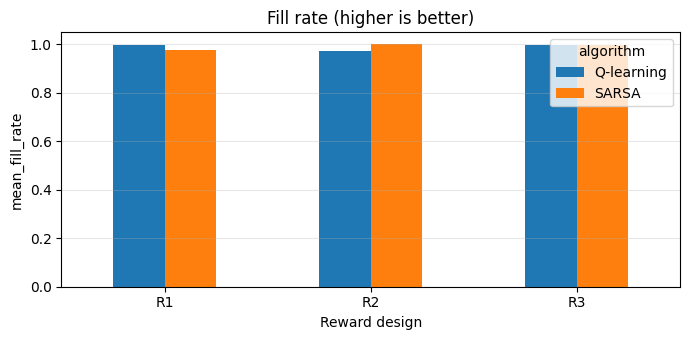

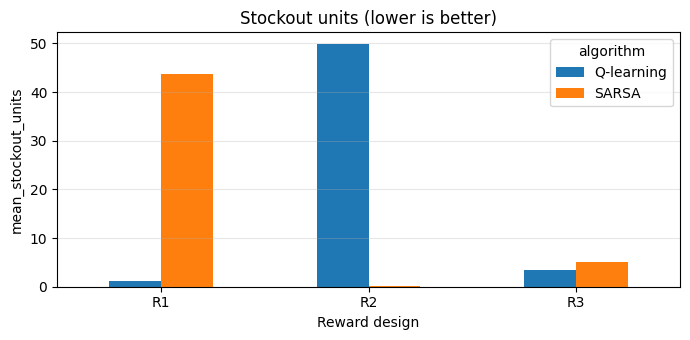

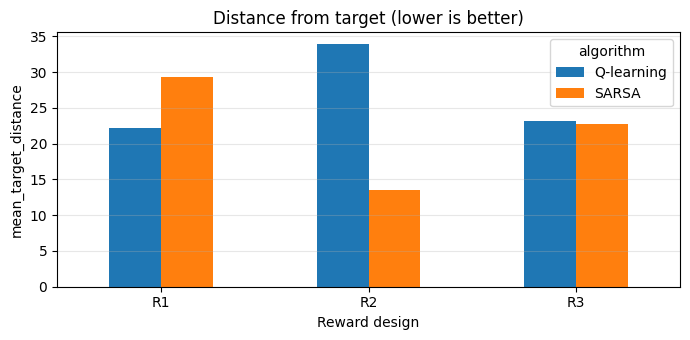

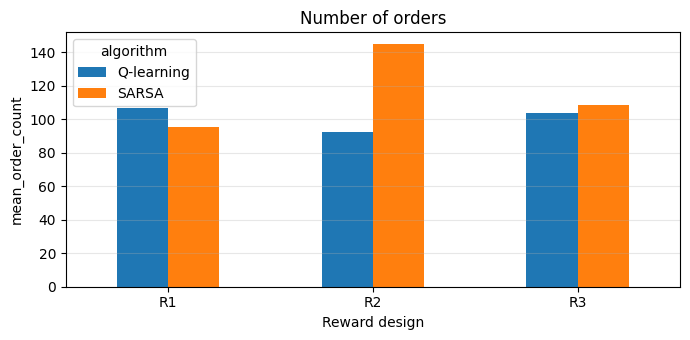

In [ ]:
for metric, title in [
    ("mean_fill_rate","Fill rate (higher is better)"),
    ("mean_stockout_units","Stockout units (lower is better)"),
    ("mean_target_distance","Distance from target (lower is better)"),
    ("mean_order_count","Number of orders")
]:
    table=summary.pivot(index="reward_design",columns="algorithm",values=metric)
    ax=table.plot(kind="bar",figsize=(7,3.5),title=title)
    ax.set_xlabel("Reward design"); ax.set_ylabel(metric); ax.grid(axis="y",alpha=.3)
    plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 11. Simple reorder-policy baseline

In [ ]:
def evaluate_baseline(scenarios):
    rows=[]
    for sid,demands in enumerate(scenarios):
        env=InventoryEnv(demands,"R2"); s=env.reset(); total=0
        while True:
            # Illustrative rule: if current stock is below TOR, order a fixed MOQ.
            action_idx = ACTIONS.index(MOQ) if env.stock < TOR else 0
            ns,r,done=env.step(action_idx); total+=r
            if done: break
            s=ns
        h=pd.DataFrame(env.history); dsum=h.demand.sum()
        rows.append({"algorithm":"Fixed reorder baseline","scenario":sid,
                     "total_reward":total,"stockout_days":(h.stockout_units>0).sum(),
                     "stockout_units":h.stockout_units.sum(),
                     "fill_rate":h.fulfilled.sum()/dsum if dsum else 1.0,
                     "mean_inventory":h.ending_stock.mean(),
                     "order_count":(h.order_qty>0).sum(),
                     "mean_target_distance":np.abs(h.ending_stock-TARGET).mean()})
    return pd.DataFrame(rows)

baseline = evaluate_baseline(eval_demands)
display(baseline.drop(columns="scenario").groupby("algorithm").mean(numeric_only=True).round(3))

,total_reward,stockout_days,stockout_units,fill_rate,mean_inventory,order_count,mean_target_distance
algorithm,,,,,,,
Fixed reorder baseline,-9.684,21.76,190.44,0.893,46.524,91.16,51.476


## 12. Inspect a single learned policy

,day,demand,arrivals,order_qty,fulfilled,stockout_units,ending_stock,reward
0,0,4,0,0,4,0,94,0.200000
1,1,9,0,0,9,0,85,0.071429
2,2,7,0,0,7,0,78,0.047619
3,3,7,0,0,7,0,71,0.035714
4,4,10,0,0,10,0,61,0.026316
5,5,10,0,40,10,0,51,0.020833
6,6,12,0,20,12,0,39,0.016667
7,7,5,0,20,5,0,34,0.015385
8,8,8,0,30,8,0,26,0.013699
9,9,4,0,40,4,0,22,0.012987


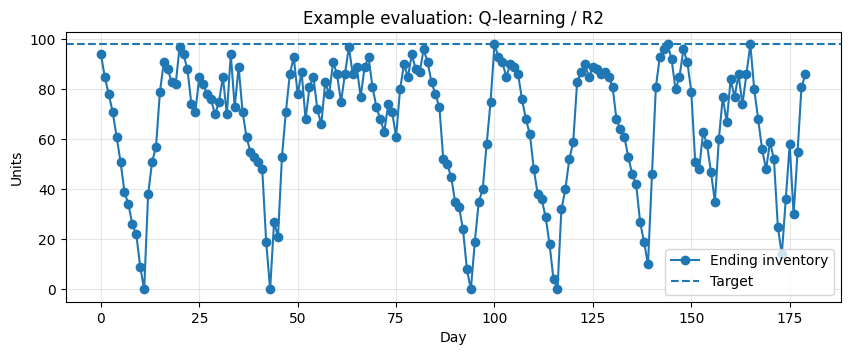

In [ ]:
Q=models[("Q-learning","R2")]
env=InventoryEnv(eval_demands[0],"R2"); s=env.reset()
while True:
    a=int(np.argmax(Q[s]))
    ns,r,done=env.step(a)
    if done: break
    s=ns
history=pd.DataFrame(env.history)
display(history.head(20))
plt.figure(figsize=(10,3.5))
plt.plot(history.day,history.ending_stock,marker="o",label="Ending inventory")
plt.axhline(TARGET,linestyle="--",label="Target")
plt.xlabel("Day"); plt.ylabel("Units"); plt.title("Example evaluation: Q-learning / R2")
plt.legend(); plt.grid(alpha=.3); plt.show()

## 13. Export result tables

In [ ]:
summary.to_csv("rl_inventory_comparison_summary.csv",index=False)
evaluation.to_csv("rl_inventory_evaluation_all_scenarios.csv",index=False)
baseline.to_csv("rl_inventory_fixed_baseline_results.csv",index=False)
print("Saved 3 CSV result files to the current notebook folder.")

Saved 3 CSV result files to the current notebook folder.
